In [2]:
import pandas as pd
import scipy.stats
import umap
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
import torch
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
from matplotlib.ticker import MaxNLocator
from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder
from BWM.models.isometric_autoencoder import get_density_proxy
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [3]:
# Set directory path and select an EID
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]


In [4]:

def iso_ae_preprocessing(pseudo_response_tensor):
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])

    X_transposed = response_matrix.T

    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)

    # Reduce features to 20 using PCA

    return X_pre_pca

pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
X = iso_ae_preprocessing(pseudo_response_tensor)

In [5]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    #diff_responses = np.diff(response_tensor_norm, axis=1)
    speed= np.median(np.abs(np.diff(z,axis=1)),axis=(0,1))
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
   # msd = np.mean(np.abs(diff_responses), axis=(0,1))
    return speed
msd = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))


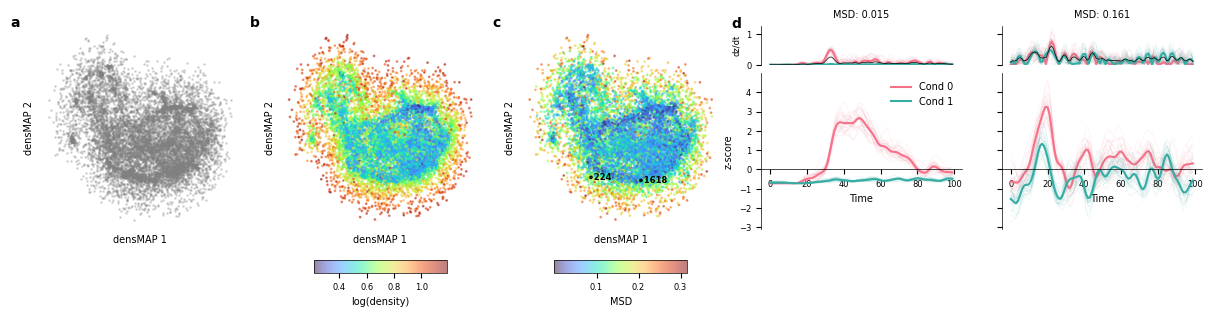

In [44]:
# Compute densmap projection
#reducer = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors=500, random_state=42)
# densmap returns the embedding and local radii (which are inversely proportional to density)
#projection = reducer.fit_transform(X)

# Calculate density proxy for coloring
# get_density_proxy returns average k-NN distance (inverse density)
density = get_density_proxy(X, k=50).numpy()
# Convert inverse density to density (log inverse for better visualization usually, or just 1/dist)


# Create figure with single row but two sub-rows for colorbars
fig = plt.figure(figsize=(15, 3.5))
# Use a 3-row GridSpec: 
# Row 0: Derivative plots (height 0.2)
# Row 1: Main response/projection plots (height 0.8)
# Row 2: Colorbars (height 0.3)
gs = gridspec.GridSpec(3, 15, height_ratios=[0.2, 0.8, 0.3], hspace=0.1, wspace=1.0)

# Panel 1: Gray points
ax0 = fig.add_subplot(gs[0:2, 0:3])
ax0.scatter(projection[:, 0], projection[:, 1], color='gray', alpha=0.25, s=1)
#ax0.set_title("DensMAP Projection (Gray)")
# Add dummy invisible color bar to maintain alignment
im0 = ax0.scatter(projection[:, 0], projection[:, 1], alpha=0)
cax0 = fig.add_subplot(gs[2, 0:3])
cbar0 = plt.colorbar(im0, cax=cax0, orientation='horizontal', shrink=0.25)
cax0.set_visible(False)
# ax0.set_xlabel("densmap 1")
# ax0.set_ylabel("densmap 2")

# Panel 2: Colored by density
ax1 = fig.add_subplot(gs[0:2, 3:6])
im1 = ax1.scatter(projection[:, 0], projection[:, 1], c=density, cmap='turbo', alpha=0.5, s=1)
# Create a nested GridSpec for the colorbar to implement shrink=0.75 and height reduction
gs_cbar1 = gridspec.GridSpecFromSubplotSpec(3, 3, subplot_spec=gs[2, 3:6], width_ratios=[0.125, 0.75, 0.125], height_ratios=[0.375, 0.25, 0.375])
cax1 = fig.add_subplot(gs_cbar1[1, 1])
cbar1 = plt.colorbar(im1, cax=cax1, orientation='horizontal')
cbar1.set_label('log(density)', fontsize=7)
#ax1.set_title("DensMAP Projection (Density)")
# ax1.set_xlabel("densmap 1")
# ax1.set_ylabel("densmap 2")

# Panel 3: Colored by MSD
ax2 = fig.add_subplot(gs[0:2, 6:9])
im2 = ax2.scatter(projection[:, 0], projection[:, 1], c=msd, cmap='turbo', alpha=0.5, s=1)
gs_cbar2 = gridspec.GridSpecFromSubplotSpec(3, 3, subplot_spec=gs[2, 6:9], width_ratios=[0.125, 0.75, 0.125], height_ratios=[0.375, 0.25, 0.375])
cax2 = fig.add_subplot(gs_cbar2[1, 1])
cbar2 = plt.colorbar(im2, cax=cax2, orientation='horizontal')
cbar2.set_label('MSD', fontsize=7)
#ax2.set_title("DensMAP Projection (MSD)")

# Mark the two selected neurons
for idx, color_marker in zip([low_msd_idx, medium_msd_idx], ['black', 'red']):
    ax2.scatter(projection[idx, 0], projection[idx, 1], facecolors='none', edgecolors='k', s=10, lw=1, zorder=10,marker = '.')
    ax2.text(projection[idx, 0], projection[idx, 1], f" {idx}", color='k', fontsize=6, fontweight='bold', va='center', ha='left', zorder=11)

# Remove axes for the first row
for i, ax in enumerate([ax0, ax1, ax2]):
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("densMAP 1", fontsize=7)
    ax.set_ylabel("densMAP 2", fontsize=7)
    
    # Add labels 'a', 'b', 'c'
    label = ['a', 'b', 'c'][i]
    ax.text(-0.1, 1.05, label, transform=ax.transAxes, fontsize=10, fontweight='bold', va='top', ha='right')

# Single neuron plots in the first row as well
# ... (rest of the logic)

# Second row: Temporal responses for two single neurons chosen by MSD
n_pseudo = pseudo_response_tensor.shape[0]
n_conds = pseudo_response_tensor.shape[1]
n_neurons = pseudo_response_tensor.shape[3]

# Choose low and medium MSD neurons
# Low MSD: around 10th percentile
# Medium MSD: around 50th percentile
msd_sorted_indices = np.argsort(msd)
low_msd_idx = msd_sorted_indices[int(0.01 * n_neurons)]
medium_msd_idx = msd_sorted_indices[int(0.85 * n_neurons)]
random_neurons = [low_msd_idx, medium_msd_idx]

palette = sns.color_palette("husl", n_conds)

# Prepare data and calculate global y-limits
neuron_data = []
global_ymin = np.inf
global_ymax = -np.inf
global_diff_ymax = -np.inf

for neuron_idx in random_neurons:
    # pseudo_response_tensor shape is (pseudo_trials, conditions, time, neurons)
    z_neuron = pseudo_response_tensor[:, :, :, neuron_idx]
    # Z-score normalization for this neuron
    z_neuron = (z_neuron - np.mean(z_neuron)) / (np.std(z_neuron) + 1e-8)
    neuron_data.append(z_neuron)
    global_ymin = min(global_ymin, np.min(z_neuron))
    global_ymax = max(global_ymax, np.max(z_neuron))
    
    # Calculate max absolute derivative for this neuron
    abs_diff = np.abs(np.diff(z_neuron, axis=2))
    global_diff_ymax = max(global_diff_ymax, np.max(abs_diff))

# Add a bit of padding to y-limits
y_range = global_ymax - global_ymin
global_ymin -= 0.05 * y_range
global_ymax += 0.05 * y_range

# Padding for derivative y-limits (start at 0)
global_diff_ymax *= 1.05

for i, (neuron_idx, z_neuron) in enumerate(zip(random_neurons, neuron_data)):
    # Add response plot
    ax = fig.add_subplot(gs[1, 9 + i*3: 9 + (i+1)*3])
    # Add derivative plot above
    ax_diff = fig.add_subplot(gs[0, 9 + i*3: 9 + (i+1)*3])
    
    for cond in range(n_conds):
        # Plot single trials
        for trial in range(n_pseudo):
            ax.plot(z_neuron[trial, cond, :], color=palette[cond], alpha=0.1, lw=0.5)
            # Calculate and plot absolute first derivative
            ax_diff.plot(np.abs(np.diff(z_neuron[trial, cond, :])), color=palette[cond], alpha=0.1, lw=0.5)
            
        # Plot mean
        mean_response = np.mean(z_neuron[:, cond, :], axis=0)
        ax.plot(mean_response, color=palette[cond], label=f'Cond {cond}', lw=1.5)
        ax_diff.plot(np.abs(np.diff(mean_response)), color=palette[cond], lw=1.5)
    
    # Add mean across all trials and conditions as a thin black line
    mean_abs_diff = np.mean(np.abs(np.diff(z_neuron, axis=2)), axis=(0, 1))
    ax_diff.plot(mean_abs_diff, color='black', lw=0.5, zorder=10)
    
    ax.set_title(f"Neuron {neuron_idx}", fontsize=7)
    ax.spines['bottom'].set_position(('data', 0))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlabel("Time")
    ax.set_ylim(global_ymin, global_ymax)
    
    # Format derivative plot
    ax_diff.set_title(f"MSD: {msd[neuron_idx]:.3f}", fontsize=7)
    ax_diff.spines['top'].set_visible(False)
    ax_diff.spines['right'].set_visible(False)
    ax_diff.spines['bottom'].set_visible(False)
    ax_diff.set_xticks([])
    ax_diff.set_ylim(0, global_diff_ymax)
    
    if i == 0:
        ax.set_ylabel("z-score")
        ax.legend(frameon=False)
        ax_diff.set_ylabel("dz/dt", fontsize=6)
        # Add label 'd'
        ax_diff.text(-0.1, 1.25, 'd', transform=ax_diff.transAxes, fontsize=10, fontweight='bold', va='top', ha='right')
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])
        ax_diff.set_yticklabels([])

plt.savefig('densmap_density_projection.png', dpi=300, bbox_inches='tight')
plt.show()
